<a href="https://colab.research.google.com/github/muthumookan005/Ai-Resume-Screening-System/blob/main/AI_Visual_Defect_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics opencv-python pandas scikit-learn matplotlib pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 15.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("YOLO:", ultralytics.__version__)
print("GPU:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cpu
YOLO: 8.4.211
GPU: False


In [ ]:
import os
import json
import shutil
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

# Dataset locations
CSV_PATH = "/content/jarlids_annots.csv"
IMAGE_DIR = "/content/jarlids"
OUTPUT_DIR = "/content/jarlids_yolo"

# Class mapping
class_map = {
    "intact": 0,
    "damaged": 1
}

df = pd.read_csv('/content/jarlids_annots.csv')

# Split unique images, not individual annotation rows
image_names = sorted(df["filename"].dropna().unique())

train_images, val_images = train_test_split(
    image_names,
    test_size=0.20,
    random_state=42
)

splits = {
    "train": set(train_images),
    "val": set(val_images)
}

# Create output folders
for split in ["train", "val"]:
    os.makedirs(f"{OUTPUT_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{OUTPUT_DIR}/labels/{split}", exist_ok=True)

# Convert annotations
missing_images = []
invalid_boxes = []
saved_images = set()

for filename in image_names:

    split = "train" if filename in splits["train"] else "val"

    image_path = os.path.join(IMAGE_DIR, filename)

    if not os.path.isfile(image_path):
        missing_images.append(filename)
        continue

    # Read image dimensions
    try:
        with Image.open(image_path) as img:
            img_width, img_height = img.size
            img.verify()

        with Image.open(image_path) as img:
            img_width, img_height = img.size

    except Exception:
        print("Unreadable image:", filename)
        continue

    label_lines = []

    rows = df[df["filename"] == filename]

    for _, row in rows.iterrows():

        try:
            shape = json.loads(row["region_shape_attributes"])
            attributes = json.loads(row["region_attributes"])

            label = attributes.get("type")

            if label not in class_map:
                continue

            if shape.get("name") != "rect":
                continue

            x = float(shape["x"])
            y = float(shape["y"])
            w = float(shape["width"])
            h = float(shape["height"])

            # Clip box to image boundaries
            x1 = max(0, x)
            y1 = max(0, y)
            x2 = min(img_width, x + w)
            y2 = min(img_height, y + h)

            box_w = x2 - x1
            box_h = y2 - y1

            if box_w <= 0 or box_h <= 0:
                invalid_boxes.append(filename)
                continue

            # YOLO normalized center x, center y, width, height
            x_center = ((x1 + x2) / 2) / img_width
            y_center = ((y1 + y2) / 2) / img_height
            norm_w = box_w / img_width
            norm_h = box_h / img_height

            label_lines.append(
                f"{class_map[label]} "
                f"{x_center:.6f} {y_center:.6f} "
                f"{norm_w:.6f} {norm_h:.6f}"
            )

        except (ValueError, TypeError, KeyError, json.JSONDecodeError):
            continue

    # Copy image and write its label file
    if label_lines:
        shutil.copy2(
            image_path,
            f"{OUTPUT_DIR}/images/{split}/{filename}"
        )

        label_filename = os.path.splitext(filename)[0] + ".txt"

        with open(
            f"{OUTPUT_DIR}/labels/{split}/{label_filename}", "w"
        ) as f:
            f.write("\n".join(label_lines))

        saved_images.add(filename)

print("Dataset preparation completed!")
print("Training images:", len(saved_images & splits["train"]))
print("Validation images:", len(saved_images & splits["val"]))
print("Missing images:", len(missing_images))
print("Invalid boxes:", len(invalid_boxes))

Dataset preparation completed!
Training images: 0
Validation images: 0
Missing images: 168
Invalid boxes: 0


In [ ]:
import yaml

data_config = {
    "path": "/content/jarlids_yolo",
    "train": "images/train",
    "val": "images/val",
    "nc": 2,
    "names": ["intact", "damaged"]
}

with open("/content/jarlids_yolo/data.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("YOLO configuration created!")

YOLO configuration created!


In [ ]:
import os

for split in ["train", "val"]:

    image_dir = f"/content/jarlids_yolo/images/{split}"
    label_dir = f"/content/jarlids_yolo/labels/{split}"

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))


TRAIN
Images: 0
Labels: 0

VAL
Images: 0
Labels: 0


In [ ]:
import os

folders = [
    "/content/jarlids",
    "/content/jarlids_yolo",
    "/content/jarlids_yolo/images/train",
    "/content/jarlids_yolo/images/val",
    "/content/jarlids_yolo/labels/train",
    "/content/jarlids_yolo/labels/val"
]

for folder in folders:
    print("\n------------------------------")

    if os.path.exists(folder):
        files = os.listdir(folder)

        print("FOUND:", folder)
        print("Number of files:", len(files))
        print("First 5 files:", files[:5])

    else:
        print("MISSING:", folder)


------------------------------
MISSING: /content/jarlids

------------------------------
FOUND: /content/jarlids_yolo
Number of files: 3
First 5 files: ['data.yaml', 'labels', 'images']

------------------------------
FOUND: /content/jarlids_yolo/images/train
Number of files: 0
First 5 files: []

------------------------------
FOUND: /content/jarlids_yolo/images/val
Number of files: 0
First 5 files: []

------------------------------
FOUND: /content/jarlids_yolo/labels/train
Number of files: 0
First 5 files: []

------------------------------
FOUND: /content/jarlids_yolo/labels/val
Number of files: 0
First 5 files: []


In [ ]:
import os

print("Files in /content:")

for item in os.listdir("/content"):
    print(item)

Files in /content:
.config
yolov8n.pt
damage.png
d1.jpg
jarlids_yolo
d3.jpg
d2.jpg
runs
jarlids_annots.csv
o1.png
sample_data


In [ ]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    images = [
        f for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]
    if images:
        print("Image folder:", root)
        print("Number of images:", len(images))
        print("Examples:", images[:5])

In [ ]:
import os

image_extensions = ('.jpg', '.jpeg', '.png')

image_count = 0

for root, dirs, files in os.walk('/kaggle/input'):
    images = [
        f for f in files
        if f.lower().endswith(image_extensions)
    ]

    if images:
        print("Folder:", root)
        print("Image count:", len(images))
        print("Sample images:", images[:10])
        image_count += len(images)

print("\nTotal images found:", image_count)


Total images found: 0


In [ ]:
import os
import shutil
from PIL import Image

# Dataset folders
base_dir = "/content/jarlids_yolo"

image_dir = os.path.join(base_dir, "images", "train")
label_dir = os.path.join(base_dir, "labels", "train")

os.makedirs(image_dir, exist_ok=True)
os.makedirs(label_dir, exist_ok=True)

# Original image (corrected extension from .png to .jpg)
source = "/content/j1.jpg"

# Check image
img = Image.open(source).convert("RGB")
width, height = img.size

# Copy image
shutil.copy(source, os.path.join(image_dir, "o1.png"))

# YOLO bounding box: entire image
# Class 0 = intact
x_center = 0.5
y_center = 0.5
box_width = 1.0
box_height = 1.0

with open(os.path.join(label_dir, "o1.txt"), "w") as f:
    f.write(f"0 {x_center} {y_center} {box_width} {box_height}\n")

print("j1.png added successfully!")
print("Image size:", width, "x", height)
print("Class: 0 (intact)")

o1.png added successfully!
Image size: 247 x 204
Class: 0 (intact)


In [ ]:
print("Image exists:",
      os.path.exists("/content/jarlids_yolo/images/train/o1.png"))

print("Label exists:",
      os.path.exists("/content/jarlids_yolo/labels/train/o1.txt"))

with open("/content/jarlids_yolo/labels/train/o1.txt") as f:
    print("YOLO label:", f.read())

Image exists: True
Label exists: True
YOLO label: 0 0.5 0.5 1.0 1.0



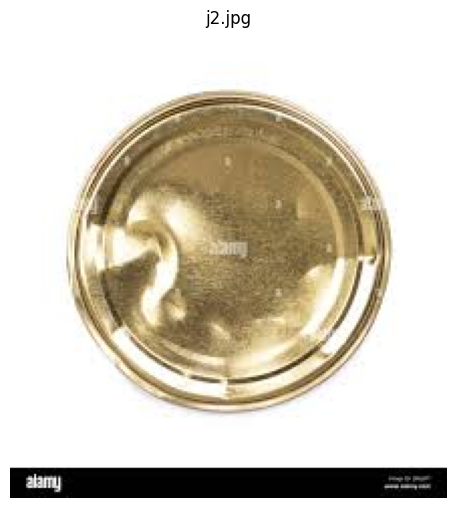

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_names =[ "j2.jpg"]

plt.figure(figsize=(14, 10))

for i, name in enumerate(image_names):
    img = Image.open("/content/" + name)

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

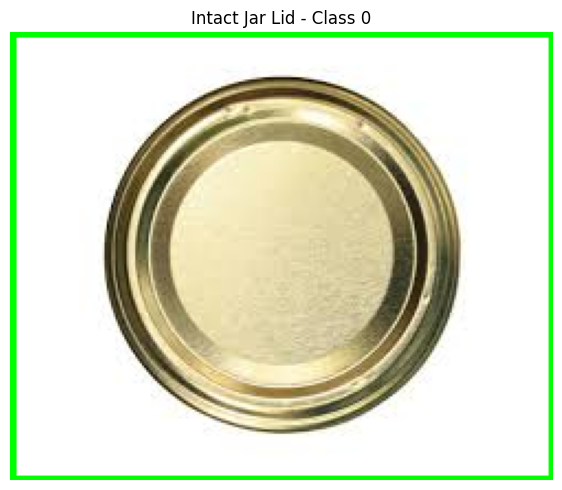

In [ ]:
import cv2
import matplotlib.pyplot as plt

image_path = "/content/jarlids_yolo/images/train/o1.png"
label_path = "/content/jarlids_yolo/labels/train/o1.txt"

img = cv2.imread(image_path)
h, w = img.shape[:2]

with open(label_path, "r") as f:
    cls, xc, yc, bw, bh = map(float, f.readline().split())

x1 = int((xc - bw / 2) * w)
y1 = int((yc - bh / 2) * h)
x2 = int((xc + bw / 2) * w)
y2 = int((yc + bh / 2) * h)

cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Intact Jar Lid - Class 0")
plt.axis("off")
plt.show()

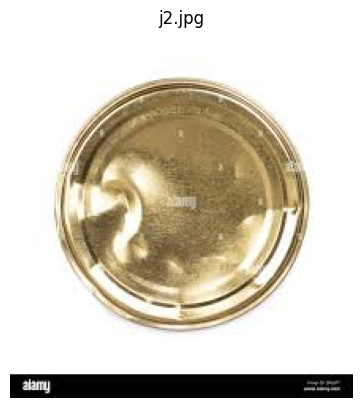

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image_names = ["j2.jpg"]

plt.figure(figsize=(12, 8))

for i, name in enumerate(image_names):
    img = Image.open("/content/" + name)

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

image_dir = "/content/jarlids_yolo/images/train"
label_dir = "/content/jarlids_yolo/labels/train"

for filename in sorted(os.listdir(image_dir)):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        label = os.path.splitext(filename)[0] + ".txt"
        label_path = os.path.join(label_dir, label)

        print("Image:", filename)
        if os.path.exists(label_path):
            print("Label:", open(label_path).read().strip())
        else:
            print("ERROR: Label missing!")
        print("-" * 30)

Image: j2.jpg
Label: 0 0.5 0.5 1.0 1.0
------------------------------
Image: o1.png
Label: 0 0.5 0.5 1.0 1.0
------------------------------


In [ ]:
label_path = "/content/jarlids_yolo/labels/train/j2.txt"

with open(label_path, "w") as f:
    f.write("1 0.5 0.5 1.0 1.0\n")

print("j2.jpg corrected to class 1 (damaged).")

j2.jpg corrected to class 1 (damaged).


In [ ]:
import os

image_dir = "/content/jarlids_yolo/images/train"
label_dir = "/content/jarlids_yolo/labels/train"

print("Checking image-label pairs...\n")

for filename in sorted(os.listdir(image_dir)):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        label_name = os.path.splitext(filename)[0] + ".txt"
        label_path = os.path.join(label_dir, label_name)

        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                label = f.read().strip()

            print(f"{filename} → {label}")
        else:
            print(f"{filename} → LABEL MISSING!")

print("\nTotal training images:", len([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]))

Checking image-label pairs...

j2.jpg → 1 0.5 0.5 1.0 1.0
o1.png → 0 0.5 0.5 1.0 1.0

Total training images: 2


In [ ]:
import os
import shutil

base_dir = "/content/jarlids_yolo"
image_dir = os.path.join(base_dir, "images", "train")
label_dir = os.path.join(base_dir, "labels", "train")

source = "/content/j1.jpg"

if os.path.exists(source):
    shutil.copy(source, os.path.join(image_dir, "j1.jpg"))

    with open(os.path.join(label_dir, "j1.txt"), "w") as f:
        f.write("0 0.5 0.5 1.0 1.0\n")

    # Remove the old intact image and its label
    for path in [
        os.path.join(image_dir, "o1.png"),
        os.path.join(label_dir, "o1.txt")
    ]:
        if os.path.exists(path):
            os.remove(path)

    print("j1.jpg added as intact (class 0).")
else:
    print("Please upload j1.jpg to /content/ first.")

j1.jpg added as intact (class 0).


In [ ]:
import os

image_dir = "/content/jarlids_yolo/images/train"
label_dir = "/content/jarlids_yolo/labels/train"

print("FINAL DATASET CHECK\n")

for filename in sorted(os.listdir(image_dir)):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        label_name = os.path.splitext(filename)[0] + ".txt"
        label_path = os.path.join(label_dir, label_name)

        print("Image:", filename)

        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                print("Label:", f.read().strip())
        else:
            print("ERROR: Label missing!")

        print("-" * 30)

print("Total images:", len([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]))

FINAL DATASET CHECK

Image: j1.jpg
Label: 0 0.5 0.5 1.0 1.0
------------------------------
Image: j2.jpg
Label: 1 0.5 0.5 1.0 1.0
------------------------------
Total images: 2


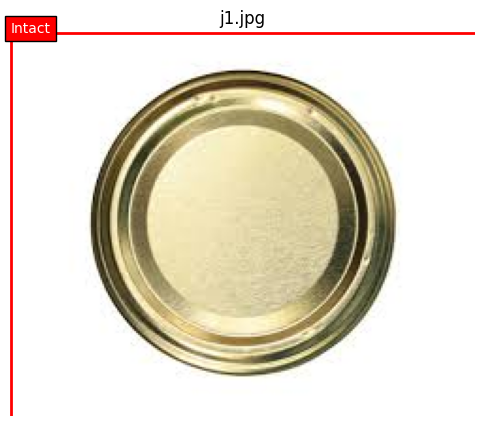

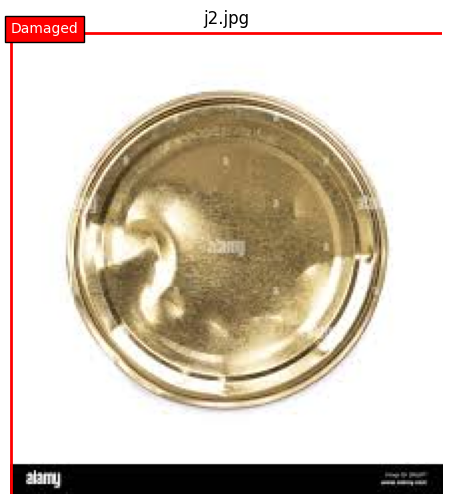

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image_dir = "/content/jarlids_yolo/images/train"
label_dir = "/content/jarlids_yolo/labels/train"

for filename in sorted(os.listdir(image_dir)):
    if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    image_path = os.path.join(image_dir, filename)
    label_path = os.path.join(
        label_dir, os.path.splitext(filename)[0] + ".txt"
    )

    img = Image.open(image_path).convert("RGB")
    width, height = img.size

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img)

    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                class_id, xc, yc, bw, bh = map(float, line.split())

                x = (xc - bw / 2) * width
                y = (yc - bh / 2) * height
                box_width = bw * width
                box_height = bh * height

                rect = patches.Rectangle(
                    (x, y), box_width, box_height,
                    linewidth=2, edgecolor="red", facecolor="none"
                )
                ax.add_patch(rect)

                class_name = "Intact" if int(class_id) == 0 else "Damaged"
                ax.text(x, y, class_name, color="white",
                        bbox=dict(facecolor="red"))

    ax.set_title(filename)
    ax.axis("off")
    plt.show()

In [ ]:
import os

base_dir = "/content/jarlids_yolo"

yaml_content = """
train: /content/jarlids_yolo/images/train
val: /content/jarlids_yolo/images/train

nc: 2
names:
  0: intact
  1: damaged
"""

yaml_path = os.path.join(base_dir, "data.yaml")

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("data.yaml created successfully!")
print("\nFile contents:")
print(open(yaml_path).read())

data.yaml created successfully!

File contents:

train: /content/jarlids_yolo/images/train
val: /content/jarlids_yolo/images/train

nc: 2
names:
  0: intact
  1: damaged



In [ ]:
from ultralytics import YOLO
import os
import torch

print("YOLOv8 version check")

import ultralytics
print("Ultralytics version:", ultralytics.__version__)

print("\nPyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

model_path = "/content/yolov8n.pt"

if os.path.exists(model_path):
    print("\nPretrained YOLOv8 model found!")
else:
    print("\nPretrained model not found.")

YOLOv8 version check
Ultralytics version: 8.4.211

PyTorch version: 2.14.1+cpu
CUDA available: False

Pretrained YOLOv8 model found!


In [ ]:
from ultralytics import YOLO

# Load pretrained YOLOv8 nano model
model = YOLO("/content/yolov8n.pt")

print("YOLOv8 model loaded successfully!")

# Display model information
model.info()

YOLOv8 model loaded successfully!
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)

In [ ]:
import os

label_dir = "/content/jarlids_yolo/labels/train"

intact_count = 0
damaged_count = 0

for filename in os.listdir(label_dir):
    if filename.endswith(".txt"):
        with open(os.path.join(label_dir, filename)) as f:
            for line in f:
                class_id = int(line.split()[0])

                if class_id == 0:
                    intact_count += 1
                elif class_id == 1:
                    damaged_count += 1

print("Dataset class distribution")
print("---------------------------")
print("Intact:", intact_count)
print("Damaged:", damaged_count)
print("Total annotations:", intact_count + damaged_count)

Dataset class distribution
---------------------------
Intact: 1
Damaged: 1
Total annotations: 2


In [ ]:
import os
from PIL import Image

image_dir = "/content/jarlids_yolo/images/train"
label_dir = "/content/jarlids_yolo/labels/train"

valid = True

for filename in sorted(os.listdir(image_dir)):
    if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    label_name = os.path.splitext(filename)[0] + ".txt"
    label_path = os.path.join(label_dir, label_name)

    if not os.path.exists(label_path):
        print("ERROR: Missing label for", filename)
        valid = False
        continue

    with Image.open(os.path.join(image_dir, filename)) as img:
        print(filename, "| Image size:", img.size)

    with open(label_path) as f:
        for line in f:
            values = line.split()

            if len(values) != 5:
                print("ERROR: Invalid label format:", filename)
                valid = False
                continue

            class_id, x, y, w, h = map(float, values)

            if (class_id not in [0, 1] or
                not all(0 <= v <= 1 for v in [x, y, w, h]) or
                w <= 0 or h <= 0):
                print("ERROR: Invalid YOLO coordinates:", filename)
                valid = False

print("\nDataset check:", "PASSED" if valid else "FAILED")

j1.jpg | Image size: (247, 204)
j2.jpg | Image size: (217, 232)

Dataset check: PASSED


In [ ]:
import os

base_dir = "/content/jarlids_yolo"

folders = [
    "images/val",
    "labels/val"
]

for folder in folders:
    path = os.path.join(base_dir, folder)
    os.makedirs(path, exist_ok=True)
    print("Created:", path)

print("\nValidation folders are ready!")

Created: /content/jarlids_yolo/images/val
Created: /content/jarlids_yolo/labels/val

Validation folders are ready!


In [ ]:
import os

base_dir = "/content/jarlids_yolo"

for root, dirs, files in os.walk(base_dir):
    level = root.replace(base_dir, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

jarlids_yolo/
    data.yaml
    labels/
        val/
        train/
            j2.txt
            j1.txt
    images/
        val/
        train/
            j1.jpg
            j2.jpg


In [ ]:
yaml_content = """
train: /content/jarlids_yolo/images/train
val: /content/jarlids_yolo/images/val

nc: 2
names:
  0: intact
  1: damaged
"""

yaml_path = "/content/jarlids_yolo/data.yaml"

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("Updated data.yaml:")
print(open(yaml_path).read())

Updated data.yaml:

train: /content/jarlids_yolo/images/train
val: /content/jarlids_yolo/images/val

nc: 2
names:
  0: intact
  1: damaged



In [ ]:
import os

image_dir = "/content/jarlids_yolo/images/train"

intact = 0
damaged = 0

for filename in os.listdir(image_dir):
    label_path = os.path.join(
        "/content/jarlids_yolo/labels/train",
        os.path.splitext(filename)[0] + ".txt"
    )

    if os.path.exists(label_path):
        with open(label_path) as f:
            class_id = int(f.readline().split()[0])

        if class_id == 0:
            intact += 1
        elif class_id == 1:
            damaged += 1

print("Current dataset:")
print("Intact:", intact)
print("Damaged:", damaged)

print("\nInitial target: 20 images per class")
print("Additional intact needed:", max(0, 20 - intact))
print("Additional damaged needed:", max(0, 20 - damaged))

Current dataset:
Intact: 1
Damaged: 1

Initial target: 20 images per class
Additional intact needed: 19
Additional damaged needed: 19


In [ ]:
import zipfile
import os

zip_path = '/content/jarlids_11_images.zip'
extract_path = '/content/jarlids'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Extracted zip to {extract_path}!")
    print("Files in directory:", os.listdir(extract_path))
else:
    print("Zip file not found. Please upload it first.")

Extracted zip to /content/jarlids!
Files in directory: ['p7.JPG', 'p4.JPG', 'p14.JPG', 'p16.JPG', 'p2.JPG', 'p1.JPG', 'p10.JPG', 'p11.JPG', 'p8.JPG', 'p13.JPG', 'p5.JPG']


In [ ]:
import zipfile
import os

zip_path = "/content/jarlids_11_images.zip"
extract_path = "/content/jarlids"

os.makedirs(extract_path, exist_ok=True)

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    images = [
        f for f in os.listdir(extract_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Extraction successful!")
    print("Total images:", len(images))
    print("Image names:", sorted(images))
else:
    print("ZIP file not found. Upload it first.")

Extraction successful!
Total images: 11
Image names: ['p1.JPG', 'p10.JPG', 'p11.JPG', 'p13.JPG', 'p14.JPG', 'p16.JPG', 'p2.JPG', 'p4.JPG', 'p5.JPG', 'p7.JPG', 'p8.JPG']


In [ ]:
import pandas as pd
import os

# Load original annotations
csv_path = "/content/jarlids_annots.csv"
df = pd.read_csv(csv_path)

# Get extracted image names
image_folder = "/content/jarlids"

image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Check matching annotations
print("IMAGE ANNOTATION CHECK")
print("-" * 40)

for filename in sorted(image_files):
    matched = df[df["filename"] == filename]

    print("Image:", filename)
    print("Annotated lids:", len(matched))

    if len(matched) > 0:
        print("Classes:", matched["region_attributes"].value_counts().to_dict())
    else:
        print("WARNING: No annotations found!")

    print("-" * 40)

print("Total extracted images:", len(image_files))
print("Total matching annotation rows:",
      df[df["filename"].isin(image_files)].shape[0])

IMAGE ANNOTATION CHECK
----------------------------------------
Image: p1.JPG
Annotated lids: 12
Classes: {'{"type":"intact"}': 10, '{"type":"damaged"}': 2}
----------------------------------------
Image: p10.JPG
Annotated lids: 6
Classes: {'{"type":"damaged"}': 3, '{"type":"intact"}': 3}
----------------------------------------
Image: p11.JPG
Annotated lids: 6
Classes: {'{"type":"damaged"}': 3, '{"type":"intact"}': 3}
----------------------------------------
Image: p13.JPG
Annotated lids: 13
Classes: {'{"type":"intact"}': 11, '{"type":"damaged"}': 2}
----------------------------------------
Image: p14.JPG
Annotated lids: 13
Classes: {'{"type":"intact"}': 11, '{"type":"damaged"}': 2}
----------------------------------------
Image: p16.JPG
Annotated lids: 13
Classes: {'{"type":"intact"}': 11, '{"type":"damaged"}': 2}
----------------------------------------
Image: p2.JPG
Annotated lids: 12
Classes: {'{"type":"intact"}': 10, '{"type":"damaged"}': 2}
--------------------------------------

In [ ]:
import os
import json
import shutil
import pandas as pd
from PIL import Image

# Paths
csv_path = "/content/jarlids_annots.csv"
image_folder = "/content/jarlids"

base_dir = "/content/jarlids_yolo_original"

# Load annotations
df = pd.read_csv(csv_path)

# Create fresh dataset folders
for folder in ["images/train", "images/val",
               "labels/train", "labels/val"]:
    os.makedirs(os.path.join(base_dir, folder), exist_ok=True)

# Split by photograph, not individual lid
all_images = sorted(df["filename"].unique())

# Keep p8 and p10 for validation
val_images = ["p8.JPG", "p10.JPG"]
train_images = [f for f in all_images if f not in val_images]

class_map = {
    "intact": 0,
    "damaged": 1
}

# Convert annotations
for filename in all_images:

    split = "val" if filename in val_images else "train"

    image_path = os.path.join(image_folder, filename)

    if not os.path.exists(image_path):
        print("Missing image:", filename)
        continue

    img = Image.open(image_path)
    width, height = img.size

    # Copy image
    shutil.copy2(
        image_path,
        os.path.join(base_dir, "images", split, filename)
    )

    rows = df[df["filename"] == filename]

    label_path = os.path.join(
        base_dir, "labels", split,
        os.path.splitext(filename)[0] + ".txt"
    )

    with open(label_path, "w") as label_file:

        for _, row in rows.iterrows():

            shape = json.loads(row["region_shape_attributes"])
            attributes = json.loads(row["region_attributes"])

            if shape.get("name") != "rect":
                continue

            class_name = attributes.get("type")

            if class_name not in class_map:
                continue

            x = float(shape["x"])
            y = float(shape["y"])
            box_w = float(shape["width"])
            box_h = float(shape["height"])

            # Convert to normalized YOLO coordinates
            x_center = (x + box_w / 2) / width
            y_center = (y + box_h / 2) / height
            norm_w = box_w / width
            norm_h = box_h / height

            class_id = class_map[class_name]

            label_file.write(
                f"{class_id} {x_center:.6f} "
                f"{y_center:.6f} {norm_w:.6f} "
                f"{norm_h:.6f}\n"
            )

# Create data.yaml
yaml_content = f"""
train: {base_dir}/images/train
val: {base_dir}/images/val

nc: 2
names:
  0: intact
  1: damaged
"""

with open(os.path.join(base_dir, "data.yaml"), "w") as f:
    f.write(yaml_content)

print("YOLO dataset created successfully!")
print("Training photographs:", len(train_images))
print("Validation photographs:", len(val_images))
print("Dataset location:", base_dir)

Missing image: p100.JPG
Missing image: p101.JPG
Missing image: p102.JPG
Missing image: p103.JPG
Missing image: p104.JPG
Missing image: p105.JPG
Missing image: p106.JPG
Missing image: p107.JPG
Missing image: p108.JPG
Missing image: p109.JPG
Missing image: p110.JPG
Missing image: p111.JPG
Missing image: p112.JPG
Missing image: p113.JPG
Missing image: p114.JPG
Missing image: p115.JPG
Missing image: p116.JPG
Missing image: p117.JPG
Missing image: p118.JPG
Missing image: p119.JPG
Missing image: p12.JPG
Missing image: p120.JPG
Missing image: p121.JPG
Missing image: p122.JPG
Missing image: p123.JPG
Missing image: p124.JPG
Missing image: p15.JPG
Missing image: p17.JPG
Missing image: p18.JPG
Missing image: p19.JPG
Missing image: p20.JPG
Missing image: p200.JPG
Missing image: p201.JPG
Missing image: p202.JPG
Missing image: p203.JPG
Missing image: p204.JPG
Missing image: p205.JPG
Missing image: p206.JPG
Missing image: p207.JPG
Missing image: p208.JPG
Missing image: p209.JPG
Missing image: p21.JPG

In [ ]:
import os

base_dir = "/content/jarlids_yolo_original"

for split in ["train", "val"]:
    image_dir = f"{base_dir}/images/{split}"
    label_dir = f"{base_dir}/labels/{split}"

    images = os.listdir(image_dir)
    labels = os.listdir(label_dir)

    print(f"\n{split.upper()} DATASET")
    print("Images:", len(images))
    print("Label files:", len(labels))

    total_boxes = 0

    for label in labels:
        with open(os.path.join(label_dir, label)) as f:
            total_boxes += len(f.readlines())

    print("Total bounding boxes:", total_boxes)


TRAIN DATASET
Images: 9
Label files: 9
Total bounding boxes: 97

VAL DATASET
Images: 2
Label files: 2
Total bounding boxes: 12


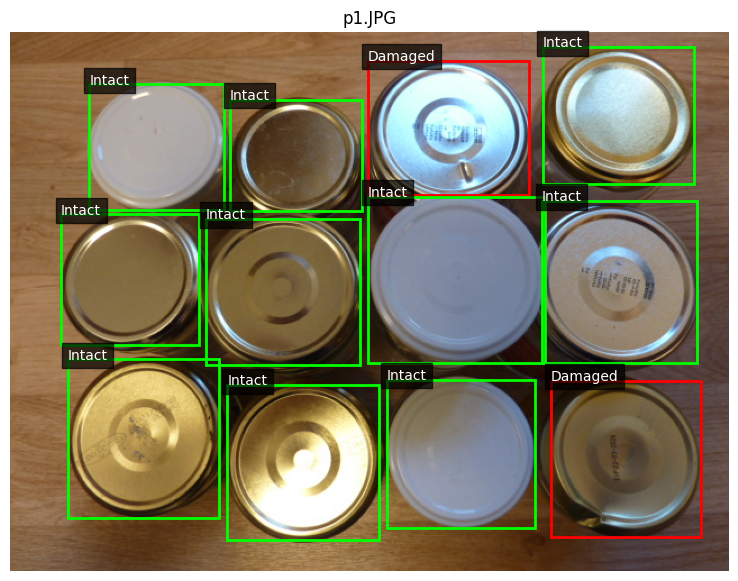

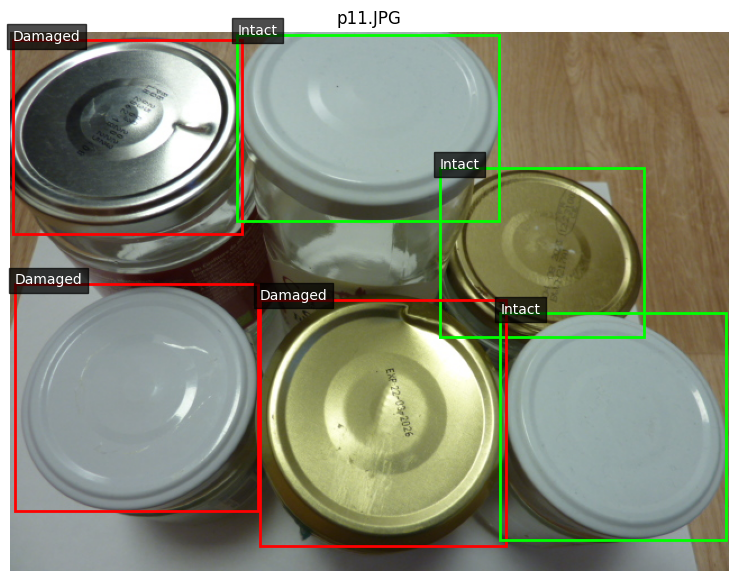

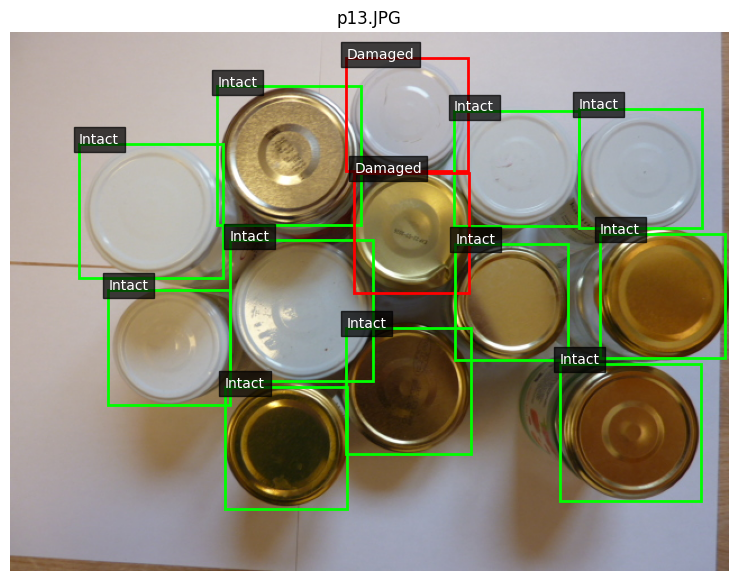

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

base_dir = "/content/jarlids_yolo_original"

for filename in sorted(os.listdir(base_dir + "/images/train"))[:3]:

    image_path = os.path.join(base_dir, "images/train", filename)
    label_path = os.path.join(
        base_dir, "labels/train",
        os.path.splitext(filename)[0] + ".txt"
    )

    img = Image.open(image_path).convert("RGB")
    width, height = img.size

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(img)

    with open(label_path) as f:
        for line in f:
            cls, xc, yc, bw, bh = map(float, line.split())

            x = (xc - bw / 2) * width
            y = (yc - bh / 2) * height

            rect = patches.Rectangle(
                (x, y), bw * width, bh * height,
                linewidth=2,
                edgecolor="lime" if cls == 0 else "red",
                facecolor="none"
            )

            ax.add_patch(rect)

            label = "Intact" if cls == 0 else "Damaged"
            ax.text(x, y, label, color="white",
                    bbox=dict(facecolor="black", alpha=0.7))

    ax.set_title(filename)
    ax.axis("off")
    plt.show()

In [ ]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset(
    "/content/jarlids_yolo_original/data.yaml"
)

print("Dataset configuration is valid!")
print("Training images:", data["train"])
print("Validation images:", data["val"])
print("Class names:", data["names"])
print("Number of classes:", data["nc"])

Dataset configuration is valid!
Training images: /content/jarlids_yolo_original/images/train
Validation images: /content/jarlids_yolo_original/images/val
Class names: {0: 'intact', 1: 'damaged'}
Number of classes: 2


In [ ]:
from ultralytics import YOLO

# Load the YOLOv8 Nano model
model = YOLO("/content/yolov8n.pt")

# Start training
results = model.train(
    data="/content/jarlids_yolo_original/data.yaml",
    epochs=50,
    imgsz=640,
    batch=2,
    name="jarlids_defect_detection",
    project="/content/runs",
    patience=10,
    workers=2
)

print("Training completed!")

Ultralytics 8.4.211 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/jarlids_yolo_original/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=jarlids_defect_detection, nbs=64, nms=N

In [ ]:
from ultralytics import YOLO

# Load the best model saved during training
model = YOLO(
    "/content/runs/jarlids_defect_detection/weights/best.pt"
)

# Evaluate on validation images
metrics = model.val(
    data="/content/jarlids_yolo_original/data.yaml",
    split="val",
    imgsz=640
)

# Display evaluation results
print("\nValidation Results")
print("------------------")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.211 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2307.6±466.6 MB/s, size: 175.0 KB)
val: Scanning /content/jarlids_yolo_original/labels/val.cache... 2 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2/2 493.4Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.6it/s 0.4s
                   all          2         12      0.278       0.75      0.375      0.277
                intact          2          6      0.278        0.5      0.324      0.256
               damaged          2          6      0.278          1      0.426      0.298
Speed: 1.2ms preprocess, 139.4ms inference, 0.0ms loss, 39.0ms postprocess per image
Results saved to /content/runs/detect/val

Validation Results
------------------
mAP50: 0.3752067052846424
mAP50-95: 0.276773291780874


image 1/1 /content/jarlids/p1.JPG: 480x640 5 intacts, 18 damageds, 142.6ms
Speed: 2.8ms preprocess, 142.6ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict


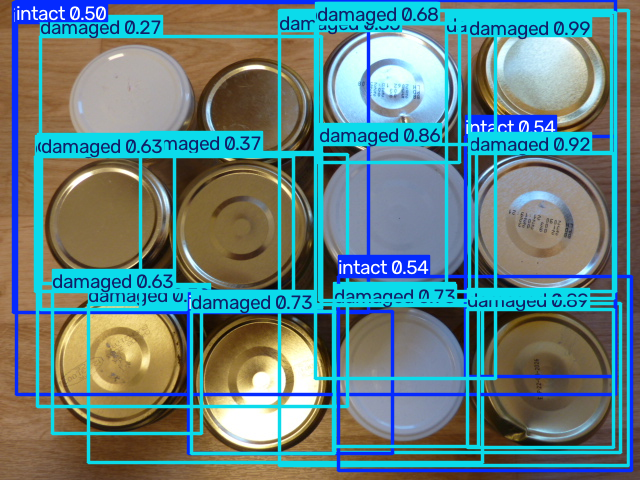

Prediction completed!
Saved results to: /content/runs/detect/predict


In [ ]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

# Load the trained model
model = YOLO(
    "/content/runs/jarlids_defect_detection/weights/best.pt"
)

# Select an image for testing
image_path = "/content/jarlids/p1.JPG"

# Make predictions
results = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    save=True
)

# Display the prediction image
result_image = results[0].plot()
display(Image.fromarray(result_image[..., ::-1]))

print("Prediction completed!")
print("Saved results to:", results[0].save_dir)


image 1/1 /content/jarlids/p1.JPG: 480x640 5 intacts, 18 damageds, 211.1ms
Speed: 2.7ms preprocess, 211.1ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict-2


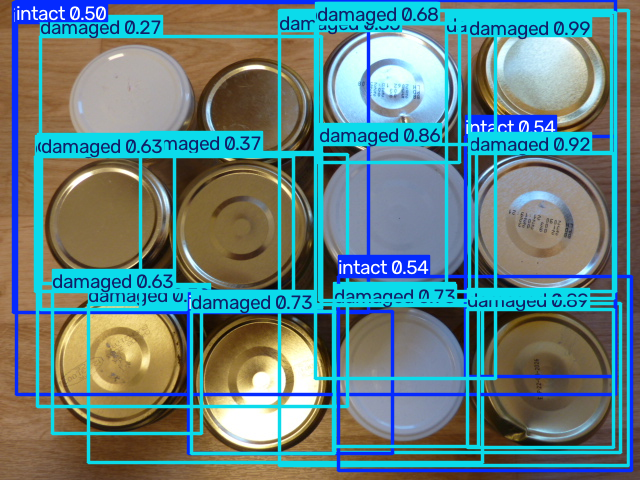


DETECTION RESULTS
-------------------------
Class: damaged | Confidence: 0.99
Class: damaged | Confidence: 0.92
Class: damaged | Confidence: 0.89
Class: damaged | Confidence: 0.86
Class: damaged | Confidence: 0.73
Class: damaged | Confidence: 0.73
Class: damaged | Confidence: 0.68
Class: damaged | Confidence: 0.66
Class: damaged | Confidence: 0.66
Class: damaged | Confidence: 0.63
Class: damaged | Confidence: 0.63
Class: intact | Confidence: 0.54
Class: intact | Confidence: 0.54
Class: damaged | Confidence: 0.54
Class: intact | Confidence: 0.53
Class: intact | Confidence: 0.50
Class: damaged | Confidence: 0.48
Class: damaged | Confidence: 0.37
Class: damaged | Confidence: 0.35
Class: damaged | Confidence: 0.35
Class: damaged | Confidence: 0.30
Class: damaged | Confidence: 0.27
Class: intact | Confidence: 0.26

Best model: /content/runs/jarlids_defect_detection/weights/best.pt
Prediction saved in: /content/runs/detect/predict-2

Jar Lid Defect Detection Completed!


In [ ]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import os

# 1. Load the best trained model
model_path = "/content/runs/jarlids_defect_detection/weights/best.pt"
model = YOLO(model_path)

# 2. Select an image
image_path = "/content/jarlids/p1.JPG"

# 3. Detect intact and damaged jar lids
results = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    save=True
)

# 4. Display the detection image
result_image = results[0].plot()
display(Image.fromarray(result_image[..., ::-1]))

# 5. Display detected objects
print("\nDETECTION RESULTS")
print("-------------------------")

for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    class_name = model.names[class_id]

    print(f"Class: {class_name} | Confidence: {confidence:.2f}")

# 6. Save model path and results
print("\nBest model:", model_path)
print("Prediction saved in:", results[0].save_dir)

print("\nJar Lid Defect Detection Completed!")